In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_DIR  = '/content/drive/MyDrive/FAB_AMR_Project'
SIM_DIR      = f'{PROJECT_DIR}/04_simulator'
DATA_DIR     = f'{SIM_DIR}/data'
OUTPUT_DIR   = f'{SIM_DIR}/output'

for d in [SIM_DIR, DATA_DIR, OUTPUT_DIR]:
    os.makedirs(d, exist_ok=True)

print("폴더 구조 확인:")
for d in [SIM_DIR, DATA_DIR, OUTPUT_DIR]:
    print(f"  ✅ {d}")

Mounted at /content/drive
폴더 구조 확인:
  ✅ /content/drive/MyDrive/FAB_AMR_Project/04_simulator
  ✅ /content/drive/MyDrive/FAB_AMR_Project/04_simulator/data
  ✅ /content/drive/MyDrive/FAB_AMR_Project/04_simulator/output


In [2]:
!pip install openpyxl -q
import openpyxl
print("openpyxl 설치 완료!")

openpyxl 설치 완료!


In [3]:
import os

xlsx_path = f'{DATA_DIR}/SMAT_2022_Model_Data_-_LVHM_E.xlsx'

if os.path.exists(xlsx_path):
    print(f"✅ 엑셀 파일 확인: {xlsx_path}")
else:
    print("❌ 엑셀 파일 없음!")
    print(f"   아래 경로에 파일을 넣어주세요:")
    print(f"   {DATA_DIR}")
    print()
    print("   방법: 구글 드라이브에서")
    print("   FAB_AMR_Project/04_simulator/data/ 폴더에")
    print("   SMAT_2022_Model_Data_-_LVHM_E.xlsx 업로드")

✅ 엑셀 파일 확인: /content/drive/MyDrive/FAB_AMR_Project/04_simulator/data/SMAT_2022_Model_Data_-_LVHM_E.xlsx


In [4]:
import openpyxl
import json
from collections import defaultdict

def load_smat2022(xlsx_path, cell_size=2000):
    """
    SMAT2022 엑셀 → fab_layout dict 변환
    cell_size: mm 단위 격자 크기 (기본 2000mm = 2m)
    """

    wb = openpyxl.load_workbook(xlsx_path, read_only=True, data_only=True)
    print(f"엑셀 로드 완료!")
    print(f"시트: {wb.sheetnames}\n")

    # ── 1. Equipment 로드 ──
    ws = wb['Equipment']
    rows = list(ws.iter_rows(values_only=True))
    equipment = [
        {
            "name":   r[0], "tool": r[1], "bay": r[2],
            "width":  r[3] or 2090, "height": r[4] or 2090,
            "x":      r[5], "y": r[6],
        }
        for r in rows[1:] if r[0] and r[5] is not None
    ]
    print(f"✅ Equipment: {len(equipment)}개")

    # ── 2. Port 로드 ──
    ws = wb['Port']
    rows = list(ws.iter_rows(values_only=True))
    ports = [
        {
            "name": r[0], "port_type": r[2],
            "eqp_name": r[3], "rail_name": r[4], "distance": r[5],
        }
        for r in rows[1:] if r[0]
    ]
    print(f"✅ Port: {len(ports)}개")

    # ── 3. Bay 로드 ──
    ws = wb['Bay']
    rows = list(ws.iter_rows(values_only=True))
    bays = [
        {
            "name": r[0], "type": r[2],
            "neighbors": r[4].split(',') if r[4] else [],
        }
        for r in rows[1:] if r[0]
    ]
    print(f"✅ Bay: {len(bays)}개")

    # ── 4. VehicleType 로드 ──
    ws = wb['VehicleType']
    rows = list(ws.iter_rows(values_only=True))
    vtype = {}
    if len(rows) > 1 and rows[1][0]:
        vtype = {
            "name": rows[1][0], "size": rows[1][1],
            "max_speed": rows[1][2],
            "acceleration": rows[1][3], "deceleration": rows[1][4],
            "min_distance": rows[1][5],
        }

    ws = wb['Vehicle']
    rows = list(ws.iter_rows(values_only=True))
    vehicle_count = len([r for r in rows[1:] if r[0]])
    print(f"✅ Vehicle: {vehicle_count}대")

    # ── 5. 좌표 범위 계산 ──
    xs = [e['x'] for e in equipment]
    ys = [e['y'] for e in equipment]
    margin = cell_size * 5

    x_min = min(xs) - margin
    x_max = max(xs) + margin
    y_min = min(ys) - margin
    y_max = max(ys) + margin

    grid_w = int((x_max - x_min) / cell_size) + 1
    grid_h = int((y_max - y_min) / cell_size) + 1

    print(f"\n📐 격자 크기: {grid_w} x {grid_h}")
    print(f"   셀 크기:   {cell_size}mm ({cell_size//1000}m)")

    # ── 6. 장비 → 격자 + obstacle 변환 ──
    def mm_to_grid(x_mm, y_mm):
        gx = int((x_mm - x_min) / cell_size)
        gy = int((y_mm - y_min) / cell_size)
        return gx, gy

    def eqp_to_obstacles(eqp):
        x, y, w, h = eqp['x'], eqp['y'], eqp['width'], eqp['height']
        gx_min = max(0, int((x - w/2 - x_min) / cell_size))
        gx_max = min(grid_w-1, int((x + w/2 - x_min) / cell_size))
        gy_min = max(0, int((y - h/2 - y_min) / cell_size))
        gy_max = min(grid_h-1, int((y + h/2 - y_min) / cell_size))
        return [[gx, gy]
                for gx in range(gx_min, gx_max+1)
                for gy in range(gy_min, gy_max+1)]

    print("\n🔄 장비 → 격자 변환 중...")
    equipment_grid = []
    all_obstacles  = []

    for eqp in equipment:
        gx, gy = mm_to_grid(eqp['x'], eqp['y'])
        obs = eqp_to_obstacles(eqp)
        all_obstacles.extend(obs)
        equipment_grid.append({
            "name": eqp['name'], "tool": eqp['tool'], "bay": eqp['bay'],
            "grid_x": gx, "grid_y": gy,
            "mm_x": eqp['x'],  "mm_y": eqp['y'],
            "obstacle_cells": obs,
        })

    # 중복 제거
    obstacle_list = list({(c[0], c[1]) for c in all_obstacles})
    obstacle_list = [[c[0], c[1]] for c in obstacle_list]
    print(f"✅ obstacle 셀: {len(obstacle_list)}개")

    # ── 7. Bay별 장비 그룹 ──
    bay_groups = defaultdict(list)
    for e in equipment_grid:
        bay_groups[e['bay']].append({
            "name": e['name'],
            "grid_x": e['grid_x'],
            "grid_y": e['grid_y'],
        })

    # ── 8. 최종 dict 구성 ──
    fab_layout = {
        "meta": {
            "source": "SMAT2022 LVHM_E",
            "cell_size": cell_size,
            "grid_w": grid_w, "grid_h": grid_h,
            "x_min": x_min,   "y_min": y_min,
            "x_max": x_max,   "y_max": y_max,
        },
        "grid": {
            "width": grid_w, "height": grid_h,
            "obstacles": obstacle_list,
        },
        "equipment":     equipment_grid,
        "ports":         ports,
        "bays":          dict(bay_groups),
        "vehicle_type":  vtype,
        "vehicle_count": vehicle_count,
    }

    return fab_layout

In [5]:
# 변환 실행
fab_layout = load_smat2022(xlsx_path, cell_size=2000)

# JSON 저장
output_path = f'{OUTPUT_DIR}/fab_layout.json'
with open(output_path, 'w', encoding='utf-8') as f:
    json.dump(fab_layout, f, ensure_ascii=False, indent=2)

print(f"\n✅ 저장 완료: {output_path}")

엑셀 로드 완료!
시트: ['Address', 'ZCU', 'Rail', 'Bay', 'Equipment', 'PortType', 'Port', 'VehicleType', 'Vehicle']

✅ Equipment: 1116개
✅ Port: 22120개
✅ Bay: 43개
✅ Vehicle: 500대

📐 격자 크기: 159 x 86
   셀 크기:   2000mm (2m)

🔄 장비 → 격자 변환 중...
✅ obstacle 셀: 4690개

✅ 저장 완료: /content/drive/MyDrive/FAB_AMR_Project/04_simulator/output/fab_layout.json


In [6]:
meta = fab_layout['meta']
print("=" * 40)
print("변환 결과 요약")
print("=" * 40)
print(f"격자 크기:  {meta['grid_w']} x {meta['grid_h']}")
print(f"셀 크기:    {meta['cell_size']}mm")
print(f"장비:       {len(fab_layout['equipment'])}개")
print(f"포트:       {len(fab_layout['ports'])}개")
print(f"베이:       {len(fab_layout['bays'])}개")
print(f"obstacle:  {len(fab_layout['grid']['obstacles'])}개 셀")
print(f"차량:       {fab_layout['vehicle_count']}대")

변환 결과 요약
격자 크기:  159 x 86
셀 크기:    2000mm
장비:       1116개
포트:       22120개
베이:       42개
obstacle:  4690개 셀
차량:       500대


/tmp/ipykernel_638/2758537155.py:50: UserWarning: Glyph 51060 (\N{HANGUL SYLLABLE I}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_638/2758537155.py:50: UserWarning: Glyph 46041 (\N{HANGUL SYLLABLE DONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_638/2758537155.py:50: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_638/2758537155.py:50: UserWarning: Glyph 45733 (\N{HANGUL SYLLABLE NEUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_638/2758537155.py:50: UserWarning: Glyph 44277 (\N{HANGUL SYLLABLE GONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_638/2758537155.py:50: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_638/2758537155.py:50: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout

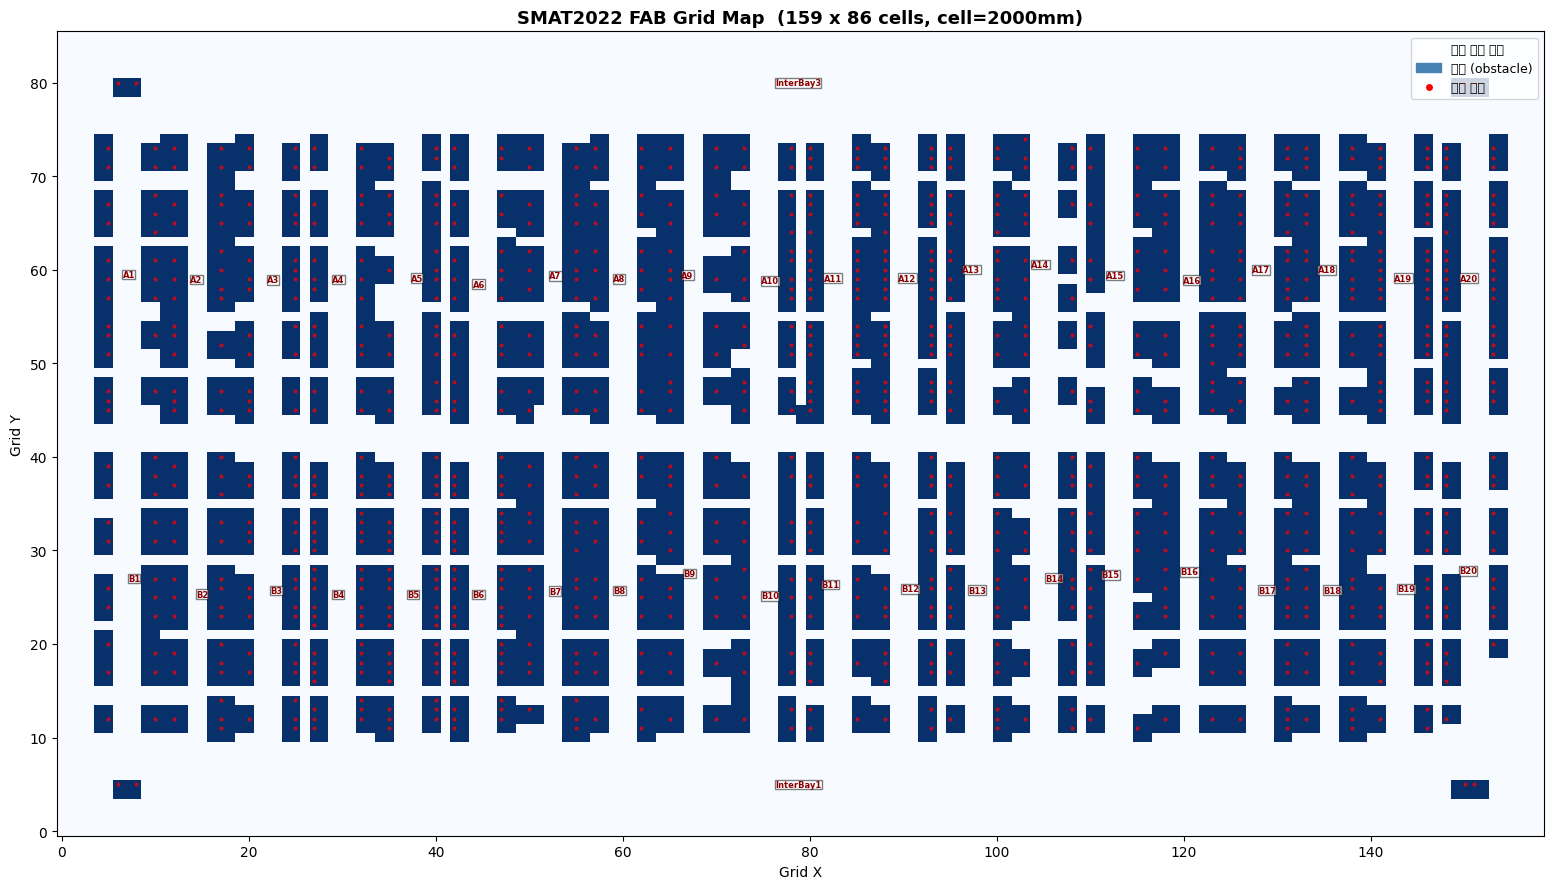

In [7]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

grid_w = fab_layout['meta']['grid_w']
grid_h = fab_layout['meta']['grid_h']

# 격자 맵 (0=이동가능, 1=obstacle)
grid = np.zeros((grid_h, grid_w))
for cell in fab_layout['grid']['obstacles']:
    gx, gy = cell
    if 0 <= gy < grid_h and 0 <= gx < grid_w:
        grid[gy][gx] = 1

# 장비 중심 좌표
eqp_xs = [e['grid_x'] for e in fab_layout['equipment']]
eqp_ys = [e['grid_y'] for e in fab_layout['equipment']]

fig, ax = plt.subplots(figsize=(18, 9))
ax.imshow(grid, cmap='Blues', origin='lower', aspect='equal')
ax.scatter(eqp_xs, eqp_ys, c='red', s=4, alpha=0.6, label='장비 중심')

# Bay 레이블
from collections import defaultdict
bay_centers = defaultdict(list)
for e in fab_layout['equipment']:
    bay_centers[e['bay']].append((e['grid_x'], e['grid_y']))

for bay, positions in bay_centers.items():
    cx = np.mean([p[0] for p in positions])
    cy = np.mean([p[1] for p in positions])
    ax.text(cx, cy, bay, fontsize=6, ha='center', va='center',
            color='darkred', fontweight='bold',
            bbox=dict(facecolor='white', alpha=0.5, pad=0.2))

legend = [
    mpatches.Patch(color='white', label='이동 가능 공간'),
    mpatches.Patch(color='steelblue', label='장비 (obstacle)'),
    plt.Line2D([0],[0], marker='o', color='w',
               markerfacecolor='red', markersize=6, label='장비 중심'),
]
ax.legend(handles=legend, loc='upper right', fontsize=9)
ax.set_title(
    f"SMAT2022 FAB Grid Map  ({grid_w} x {grid_h} cells, "
    f"cell={meta['cell_size']}mm)",
    fontsize=13, fontweight='bold'
)
ax.set_xlabel("Grid X")
ax.set_ylabel("Grid Y")
plt.tight_layout()
plt.show()